# Linear Algebra for Data Science 2026 — Lab 2, Core B
# Markov chains and PageRank

### <div align="right"> &copy; Rostyslav Hryniv, 2026, after O. Dyhdalovych & R. Hryniv, 2023 </div>

## Completed by:
*   Mariia Cherkasova
*   Andrii Polishko

**Marked at the defence:** Core B is worth 2 points; the starred extension B1 at the end is one of three routes to the extension point (see the brief).

## Why this core

How popular is a web page, a paper or a user in a social network? PageRank answers with the stationary distribution of a random walk, which is an eigenvector of a huge, sparse, non-negative matrix. This core takes you from the naive model to the version that actually runs: you will see the model fail in three different ways, repair it with one rank-one term, **predict how fast the repaired iteration converges**, and run it on a graph with $10^5$ nodes without ever forming the matrix.

**Uses:** Lecture 3.2 (stochastic matrices, Perron–Frobenius, PageRank, power iteration). Core A's `power_method` is the same algorithm; here it gets a matrix-free form.

**Rules for this notebook**
* `np.linalg.eig`/`eigvals` are allowed **only to check** results on small graphs (§1, §3, §4). Your PageRank code must not call them.
* `networkx` is used for drawing small graphs, for generating the large test graph and, once, as an independent check in §5. Do not use it to compute ranks anywhere else.
* Every number you report must be reproduced by `Restart & Run All`.

In [18]:
import sys, time, numpy as np, scipy, scipy.sparse as sp, networkx as nx, matplotlib
import matplotlib.pyplot as plt
print('python', sys.version.split()[0], '| numpy', np.__version__, '| scipy', scipy.__version__,
      '| networkx', nx.__version__, '| matplotlib', matplotlib.__version__)
rng = np.random.default_rng(2026)   # do not change the seed: the defence uses your numbers

python 3.13.16 | numpy 2.1.3 | scipy 1.16.3 | networkx 3.7 | matplotlib 3.10.0


## The convention used throughout

Pages are numbered $0,\dots,n-1$. The **adjacency matrix** $G$ has
$$
G_{jk} = 1 \iff \text{page } k \text{ links to page } j,
$$
so **column $k$ lists the out-links of page $k$**, and the number of out-links $N_k$ is the $k$-th column sum. The link matrix of Lecture 3.2 is
$$
p_{jk} = \begin{cases} 1/N_k, & k \to j,\\ 0, & \text{otherwise,}\end{cases}
$$
so $p_{jk}$ is the probability of moving **from $k$ to $j$**, and every column of $P$ with $N_k > 0$ sums to $1$. Ranks are column vectors $\mathbf{r}$, updated by $\mathbf{r}_{n+1} = P\mathbf{r}_n$.

*(Last year's notebook stated this convention backwards in one place. If you find older material online, check its convention before reusing anything.)*

In [19]:
def plot_graph(G, ranks, title=''):
    # draws the graph with arrows k -> j for G[j, k] = 1, and the ranks under the labels
    graph = nx.from_numpy_array(np.asarray(G).T, create_using=nx.DiGraph)
    pos = nx.circular_layout(graph)
    plt.figure(figsize=(5, 4))
    nx.draw(graph, pos=pos, node_size=1600, node_color='w', edgecolors='k', linewidths=2,
            connectionstyle='arc3,rad=0.1', arrowsize=18)
    nx.draw_networkx_labels(graph, pos=pos, labels={v: f'{v}\n{ranks[v]:.3f}' for v in graph.nodes()})
    plt.title(title); plt.show()

---
## 1. The random surfer

### 1.1 Implement the two building blocks
* `link_matrix(G)` returns $P$ as above. Columns of pages with no out-links ("dead ends") stay zero for now.
* `power_markov(M, r0, tol, max_iter)` iterates $\mathbf{r}_{n+1} = M\mathbf{r}_n$. Here `M` may be a matrix **or a function** `x -> M x`; that is what will let you reuse it unchanged in §5. Stop when $\|\mathbf{r}_{n+1} - \mathbf{r}_n\|_1 \le$ `tol`. Return the final vector and a history with the 1-norm increments and the sums $\mathbf{1}^\top\mathbf{r}_n$.

**Question 1.1.** Core A normalised the iterate at every step. Why is no normalisation needed here, as long as $M$ is column-stochastic?

---
Because r0 is a probability vector (sum 1), and multiplying by P keeps the sum exactly the same, because every column of P sums to 1: each page passes on all of its probability, none created and none lost. So every iterate still sums to 1 and can’t blow up or vanish, and no normalisation is needed.

---

In [20]:
def link_matrix(G):
    '''Column-stochastic link matrix P of Lecture 3.2; zero columns for dead ends.'''
    # YOUR CODE HERE
    G = np.asarray(G, dtype=float)
    N = G.sum(axis=0)
    prob = np.divide(1, N, out=np.zeros_like(N), where=N > 0)
    return G * prob

def power_markov(M, r0=None, tol=1e-10, max_iter=1000):
    def step(x):
        if callable(M):
            return M(x)
        else:
            return M @ x

    if r0 is None:
        n = M.shape[0]
        r0 = np.ones(n) / n
    r_next = step(r0)
    increments = []
    sums = []
    for i in range(max_iter):
        r0 = r_next
        r_next = step(r0)
        diff = np.linalg.norm(r_next - r0, ord=1)
        increments.append(diff)
        sums.append(r_next.sum())
        if diff <= tol:
            break
    return r_next, {'inc': np.array(increments), 'sum': np.array(sums)}

### 1.2 First test
Run the iteration on the graph below from the uniform distribution and from two other starting distributions of your choice. Check the result against the eigenvector of $P$ for $\lambda = 1$ obtained from `np.linalg.eig` (normalise it to sum 1). Which page ranks highest? Explain *from the graph* why that is reasonable.

In [21]:
G1 = np.array([[0, 1, 1, 0],
               [1, 0, 1, 1],
               [0, 1, 0, 0],
               [1, 1, 0, 0]])
# YOUR CODE HERE
print('link matrix P1:')
P1 = link_matrix(G1)
print(P1)

r_unif, hist_unif = power_markov(P1)
print('\nranks (uniform start):', r_unif)
print('number of iterations:', len(hist_unif['inc']))

r_e0, hist_e0 = power_markov(P1, r0=np.array([1., 0., 0., 0.]))
print('\nranks (start [1., 0., 0., 0.]):', r_e0)
print('number of iterations:', len(hist_e0['inc']))

r_e1, hist_e1 = power_markov(P1, r0=np.array([0., 1., 0., 0.]))
print('\nranks (start [0., 1., 0., 0.]):', r_e1)
print('number of iterations:', len(hist_e1['inc']))

print('\n------------------')

print('\ncheck the result:')
lam, V = np.linalg.eig(P1)
print('eigenvalues: ', lam.real)

i = np.argmin(np.abs(lam - 1))
v = V[:, i].real
v = v / v.sum()
print('\neigenvector for lambda = 1:', v)

print('\ndifference, uniform start:', np.linalg.norm(r_unif - v, ord=1))
print('difference, start e0:', np.linalg.norm(r_e0 - v, ord=1))
print('difference, start e1:', np.linalg.norm(r_e1 - v, ord=1))

link matrix P1:
[[0.         0.33333333 0.5        0.        ]
 [0.5        0.         0.5        1.        ]
 [0.         0.33333333 0.         0.        ]
 [0.5        0.33333333 0.         0.        ]]

ranks (uniform start): [0.20689655 0.4137931  0.13793103 0.24137931]
number of iterations: 61

ranks (start [1., 0., 0., 0.]): [0.20689655 0.4137931  0.13793103 0.24137931]
number of iterations: 62

ranks (start [0., 1., 0., 0.]): [0.20689655 0.4137931  0.13793103 0.24137931]
number of iterations: 65

------------------

check the result:
eigenvalues:  [ 1.         -0.15379711 -0.15379711 -0.69240578]

eigenvector for lambda = 1: [0.20689655 0.4137931  0.13793103 0.24137931]

difference, uniform start: 3.4571845386466293e-11
difference, start e0: 2.8514440808535824e-11
difference, start e1: 2.950756305963864e-11


---
All three starts (uniform, e0, e1) converge to the same vector r = (0.20689655 0.4137931  0.13793103 0.24137931), which matches the eigenvector of P for $\lambda = 1$ from `np.linalg.eig`.

Page 1 ranks highest, means a random surfer, clicking links forever, spends about 41% of their time on page 1. This is because it is the only page that receives links from all three other pages. In addition, page 3 links only to page 1, so it passes on all of its rank, while pages 0 and 2 split theirs between two pages.

---

---
## 2. Dead ends

### 2.1 What goes wrong
In the graph `G2` below, page 3 has no out-links. Run the iteration and plot the sums $\mathbf{1}^\top\mathbf{r}_n$ against $n$. Explain what you see using the column sums of $P$: show that $\mathbf{1}^\top\mathbf{r}_{n+1} = \mathbf{1}^\top\mathbf{r}_n - \mathbf{d}^\top\mathbf{r}_n$, where $\mathbf{d}$ marks the dead ends ($d_k = 1$ if $N_k = 0$, else $0$).

### 2.2 The repair
Let the surfer jump from a dead end to a uniformly random page:
$$
P_d := P + \tfrac1n\,\mathbf{1}\mathbf{d}^\top .
$$
Implement `fix_dead_ends(P)` and rerun. Check that $P_d$ is column-stochastic.

link matrix P2:
[[0.         0.33333333 0.5        0.        ]
 [0.5        0.         0.5        0.        ]
 [0.         0.33333333 0.         0.        ]
 [0.5        0.33333333 0.         0.        ]]

ranks (uniform start): [3.84172812e-11 4.47624638e-11 2.20800663e-11 5.05053152e-11]
number of iterations: 57


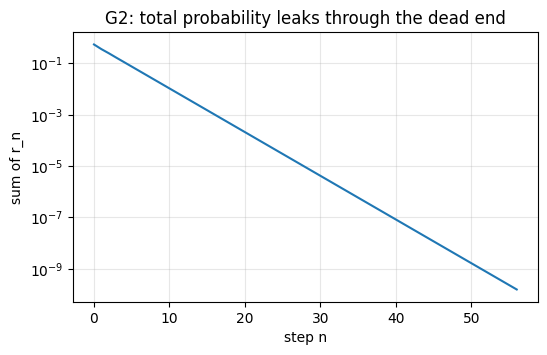

In [22]:
G2 = np.array([[0, 1, 1, 0],
               [1, 0, 1, 0],
               [0, 1, 0, 0],
               [1, 1, 0, 0]])

def fix_dead_ends(P):
    '''P_d = P + (1/n) 1 d^T (dense; for small graphs only).'''
    # YOUR CODE HERE
    n = P.shape[0]
    P_sums = P.sum(axis=0)
    is_dead = P_sums == 0
    d = is_dead.astype(float)
    P_d = P + np.outer(np.ones(n), d) / n
    return P_d



# YOUR CODE HERE
print('link matrix P2:')
P2 = link_matrix(G2)
print(P2)

r2, hist2 = power_markov(P2)
print('\nranks (uniform start):', r2)
print('number of iterations:', len(hist2['inc']))

plt.figure(figsize=(6, 3.5))
plt.semilogy(hist2['sum'])
plt.xlabel('step n')
plt.ylabel('sum of r_n')
plt.title('G2: total probability leaks through the dead end')
plt.grid(True, alpha=0.3)
plt.show()

In [23]:
print('the repair:')
P2_fixed = fix_dead_ends(P2)
print(P2_fixed)

r2_fixed, hist2_fixed = power_markov(P2_fixed)
print('\nranks (uniform start):', r2_fixed)
print('number of iterations:', len(hist2_fixed['inc']))

the repair:
[[0.         0.33333333 0.5        0.25      ]
 [0.5        0.         0.5        0.25      ]
 [0.         0.33333333 0.         0.25      ]
 [0.5        0.33333333 0.         0.25      ]]

ranks (uniform start): [0.25263158 0.28421053 0.16842105 0.29473684]
number of iterations: 19


---
The sum of probabilities goes to zero because on each iteration we lose the probability that is on page 3, since this page doesn't lead anywhere.

In terms of $P$: page 3's column is zero, so the column sums are $(1, 1, 1, 0)$, $\mathbf{1}^\top P = (\mathbf{1} - \mathbf{d})^\top$. Therefore

$$
\mathbf{1}^\top \mathbf{r}_{n+1} = (\mathbf{1}^\top P)\,\mathbf{r}_n = (\mathbf{1} - \mathbf{d})^\top \mathbf{r}_n = \mathbf{1}^\top \mathbf{r}_n - \mathbf{d}^\top \mathbf{r}_n,
$$

where $\mathbf{d}^\top \mathbf{r}_n = (\mathbf{r}_n)_3$ is the probability on page 3.

After applying `fix_dead_ends`, page 3's column became (0.25, 0.25, 0.25, 0.25): from page 3 the surfer jumps to any page with equal probability, so there's no leakage. All column sums of $P_d$ are 1, so the total probability stays 1, and the iteration converges in 19 steps to $\mathbf{r} \approx (0.253, 0.284, 0.168, 0.295)$.



---

---
## 3. When the answer is not unique, or the iteration does not settle

### 3.1 Three graphs, three problems
Run `power_markov` (on $P_d$) for the three graphs below, each from **at least three** starting distributions: the uniform one, $\mathbf{e}_0$, and one more. Use `max_iter=200`. For each graph, describe what happens. Then compute the eigenvalues of $P_d$ (here you may use `np.linalg.eigvals`), plot them in the complex plane together with the unit circle, and explain each behaviour **from the spectrum**.

* `G6`: does every page get a sensible rank? Does the iteration converge from every start?
* `G4` (a directed cycle): why does the uniform start *seem* to converge immediately?
* `G2c` (two separate parts): does the limit depend on the start?

In [24]:
G6 = np.array([[0, 1, 0, 0, 0, 1],
               [1, 0, 1, 0, 0, 0],
               [0, 0, 0, 1, 0, 0],
               [0, 0, 1, 0, 1, 1],
               [0, 0, 1, 0, 0, 1],
               [0, 0, 0, 1, 0, 0]])
G4 = np.array([[0, 1, 0, 0],
               [0, 0, 1, 0],
               [0, 0, 0, 1],
               [1, 0, 0, 0]])
G2c = np.zeros((6, 6), dtype=int)
for k, j in [(0, 1), (1, 2), (2, 0), (0, 2), (3, 4), (4, 5), (5, 3), (3, 5)]:   # link k -> j
    G2c[j, k] = 1
# YOUR CODE HERE
graphs = {'G6': G6, 'G4': G4, 'G2c': G2c}
for name, G in graphs.items():
    print('-------', name, '-------')
    print(G)
    P_d = fix_dead_ends(link_matrix(G))

    n = P_d.shape[0]
    r0_unif = np.ones(n) / n
    r0_first = np.eye(n)[0]
    r0_last = np.eye(n)[n - 1]

    r_u, hist_u = power_markov(P_d, r0=r0_unif, max_iter=200)
    print('\nranks (uniform start):', r_u)
    print('number of iterations:', len(hist_u['inc']))

    r_f, hist_f = power_markov(P_d, r0=r0_first, max_iter=200)
    print('\nranks (start on page 0):', r_f)
    print('number of iterations:', len(hist_f['inc']))

    r_l, hist_l = power_markov(P_d, r0=r0_last, max_iter=200)
    print('\nranks (start on last page):', r_l)
    print('number of iterations:', len(hist_l['inc']))
    print('\n')

------- G6 -------
[[0 1 0 0 0 1]
 [1 0 1 0 0 0]
 [0 0 0 1 0 0]
 [0 0 1 0 1 1]
 [0 0 1 0 0 1]
 [0 0 0 1 0 0]]

ranks (uniform start): [5.00000000e-01 5.00000000e-01 5.51119076e-11 9.38426905e-11
 4.31548065e-11 5.51119076e-11]
number of iterations: 134

ranks (start on page 0): [0. 1. 0. 0. 0. 0.]
number of iterations: 200

ranks (start on last page): [6.66666667e-01 3.33333333e-01 1.77517096e-15 3.02270101e-15
 1.39002917e-15 1.77517096e-15]
number of iterations: 200


------- G4 -------
[[0 1 0 0]
 [0 0 1 0]
 [0 0 0 1]
 [1 0 0 0]]

ranks (uniform start): [0.25 0.25 0.25 0.25]
number of iterations: 1

ranks (start on page 0): [0. 0. 0. 1.]
number of iterations: 200

ranks (start on last page): [0. 0. 1. 0.]
number of iterations: 200


------- G2c -------
[[0 0 1 0 0 0]
 [1 0 0 0 0 0]
 [1 1 0 0 0 0]
 [0 0 0 0 0 1]
 [0 0 0 1 0 0]
 [0 0 0 1 1 0]]

ranks (uniform start): [0.2 0.1 0.2 0.2 0.1 0.2]
number of iterations: 64

ranks (start on page 0): [0.4 0.2 0.4 0.  0.  0. ]
number of iterat

------- G6 -------
eigenvalues:  [ 1.00000000e+00+0.j         -1.00000000e+00+0.j
  8.51383073e-01+0.j          4.38570457e-17+0.j
 -4.25691536e-01+0.45859189j -4.25691536e-01-0.45859189j]


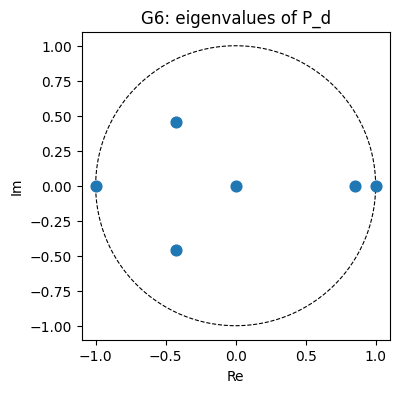



------- G4 -------
eigenvalues:  [-1.00000000e+00+0.j  8.32667268e-17+1.j  8.32667268e-17-1.j
  1.00000000e+00+0.j]


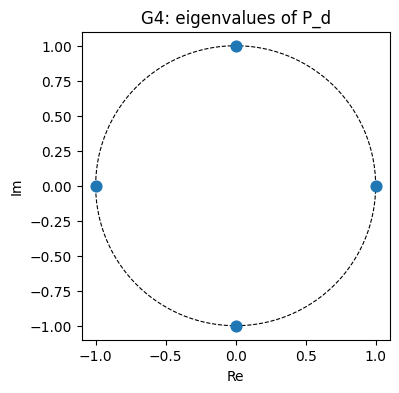



------- G2c -------
eigenvalues:  [ 1. +0.j  -0.5+0.5j -0.5-0.5j  1. +0.j  -0.5+0.5j -0.5-0.5j]


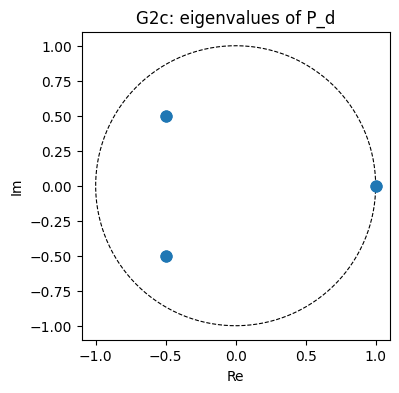

In [25]:
# eigenvalues
for name, G in graphs.items():
    print('-------', name, '-------')
    P_d = fix_dead_ends(link_matrix(G))
    n = P_d.shape[0]

    lam, V = np.linalg.eig(P_d)
    print('eigenvalues: ', lam)

    t = np.linspace(0, 2 * np.pi, 400)
    plt.figure(figsize=(4, 4))
    plt.plot(np.cos(t), np.sin(t), 'k--', lw=0.8)
    plt.scatter(lam.real, lam.imag, s=60, zorder=3)
    plt.gca().set_aspect('equal')
    plt.xlabel('Re'); plt.ylabel('Im')
    plt.title(f'{name}: eigenvalues of P_d')
    plt.show()

    print('\n')

---
1. G6

Pages 0 and 1 link only to each other, so they form a trap: the surfer can get in, but never out. Pages 2–5 slowly leak into it.

- from the uniform start all the rank ends up on pages 0 and 1, and pages 2–5 get 0.
- from the other two starts it never settles. The surfer bounces 0 to 1 to 0 to 1 forever, and the result depends on whether we stop on an even or odd step.

2. G4

It's basically one big loop: 0 to 3 to 2 to 1 to 0.

- from uniform it looks converged after 1 step. Every page passes its ¼ to the next page, so each page still has ¼. Nothing changes, but only because the start was already balanced, not because the iteration converged.
- from e0 the surfer just goes round and round, so it never settles.

3. G2c

Here we have two separate groups {0, 1, 2} and {3, 4, 5} with no links between them.

- it converges every time, but to a different answer depending on the start. probability that starts in one group stays there forever.


**Eigenvalues**

1. G6

This trap is a 2-cycle, which gives eigenvalues 1 and -1. $\lambda$ = -1 is on the unit circle, so its part never fades: the surfer bounces 0 to 1 and back and the iteration from e0 never settles. The uniform start has no −1 component, so it converges. All other eigenvalues are inside the circle and fade.

2. G4
G4 is a 4-cycle, so the eigenvalues are 1, i, -1, -i, all on the unit circle. Nothing fades, so from e0 the probability rotates forever. The uniform start is already the eigenvector for $\lambda$ = 1, so nothing changes from the first step. It didn't converge, it started at the answer.


3. G2c

G2c is two identical copies of the same small graph:
- pages 0, 1, 2 with links 0 to 1, 1 to 2, 2 to 0, 0 to 2;
- pages 3, 4, 5 with links 3 to 4, 4 to 5, 5 to 3, 3 to5, the same pattern.

Each copy on its own has eigenvalues 1 and −0.5 +- 0.5i. SO if we put two copies side by side with no links between them, we'll get each eigenvalue once per copy.


---

### 3.2 The repair: damping
With $0 < \alpha < 1$ (Google's choice was $\alpha \approx 0.85$), the surfer follows a link with probability $\alpha$ and jumps to a uniformly random page with probability $1-\alpha$:
$$
\widetilde P := \alpha P_d + \frac{1-\alpha}{n}\,\mathbf{1}\mathbf{1}^\top .
$$
*Careful: here, as in the lecture, $\alpha$ is the probability of **following a link**. Last year's notebook used $\alpha$ for the jump probability, i.e. our $1-\alpha$.*

**(a)** Show that $\widetilde P$ is column-stochastic and entrywise positive. What does Perron–Frobenius (Lecture 3.2) then guarantee?

**(b)** Prove the bound from the lecture: every eigenvalue $\lambda \ne 1$ of $\widetilde P$ satisfies $|\lambda| \le \alpha$. *Hint:* let $\widetilde P\mathbf{w} = \lambda\mathbf{w}$ with $\lambda \ne 1$. Use $\mathbf{1}^\top\widetilde P = \mathbf{1}^\top$ to show that $\mathbf{1}^\top\mathbf{w} = 0$, and conclude that $\lambda/\alpha$ is an eigenvalue of $P_d$. Why can no eigenvalue of a column-stochastic matrix exceed 1 in modulus? *(Consider the norm $\|\cdot\|_1$.)*

---
**(a)** Each column of $P_d$ sums to 1, and the jump part adds $\frac{1-\alpha}{n}$ to each of the $n$ entries of every column. So every column of $\widetilde P$ sums to

$$
\alpha \cdot 1 + n \cdot \frac{1-\alpha}{n} = \alpha + (1-\alpha) = 1.
$$

$P_d$ has no negative entries, and every entry gets $+\frac{1-\alpha}{n}$, which is $> 0$ because $\alpha < 1$. So every entry of $\widetilde P$ is at least $\frac{1-\alpha}{n} > 0$, with no zeros anywhere. So basically every page now "links" to every page, with at least a small weight.

$\widetilde P$ is entrywise positive and column-stochastic, so its largest eigenvalue is $\lambda = 1$, and Perron-Frobenius guarantees:
1. $\lambda = 1$ appears only once: there is exactly one stationary distribution, so PageRank is unique (fixes `G2c`);
2. its eigenvector is strictly positive: every page gets a positive rank (fixes `G6`, where pages 2-5 got 0);
3. every other eigenvalue has $|\lambda| < 1$: all other components fade, so the iteration converges from any start (fixes `G4`).

---
**(b)** Let $\widetilde P\mathbf{w} = \lambda\mathbf{w}$ with $\lambda \ne 1$.

1. $\mathbf{w}$ sums to 0. Multiply both sides by $\mathbf{1}^\top$ and use $\mathbf{1}^\top\widetilde P = \mathbf{1}^\top$:
$$
\mathbf{1}^\top\mathbf{w} = \mathbf{1}^\top\widetilde P\mathbf{w} = \lambda\,\mathbf{1}^\top\mathbf{w} \;\Rightarrow\; (1-\lambda)\,\mathbf{1}^\top\mathbf{w} = 0 \;\Rightarrow\; \mathbf{1}^\top\mathbf{w} = 0.
$$

2. **The jump part vanishes on $\mathbf{w}$.** Since $\frac{1-\alpha}{n}\mathbf{1}\mathbf{1}^\top\mathbf{w} = \frac{1-\alpha}{n}(\mathbf{1}^\top\mathbf{w})\,\mathbf{1} = \mathbf{0}$,
$$
\lambda\mathbf{w} = \widetilde P\mathbf{w} = \alpha P_d\mathbf{w} \;\Rightarrow\; P_d\mathbf{w} = \frac{\lambda}{\alpha}\,\mathbf{w},
$$
so $\lambda/\alpha$ is an eigenvalue of $P_d$.

3. **Eigenvalues of a column-stochastic matrix satisfy $|\mu| \le 1$.** The matrix 1-norm $\|M\|_1$ is the largest column sum, which is 1 here, and every eigenvalue satisfies $|\mu| \le \|M\|_1 = 1$.

Applying 3 to $P_d$: $|\lambda/\alpha| \le 1$, so $|\lambda| \le \alpha$.

---

### 3.3 Implement and test
Write `google_matrix(G, alpha)` (dense — small graphs only) and rerun the three graphs of §3.1 from the same starts. Does the iteration converge now, and to a unique answer? Then, for `G6`, tabulate the ranks for $\alpha \in \{0.5, 0.85, 0.99\}$. What happens to pages 2–5 as $\alpha \to 1$, and why?

In [26]:
def google_matrix(G, alpha=0.85):
    # YOUR CODE HERE
    P = link_matrix(G)
    P_d = fix_dead_ends(P)
    n = P.shape[0]
    rdm_jump = np.ones((n, n)) * ((1 - alpha) / n)
    return alpha * P_d + rdm_jump

# YOUR CODE HERE
graphs = {'G6': G6, 'G4': G4, 'G2c': G2c}
for name, G in graphs.items():
    print('-------', name, '-------')
    print(G)
    P = google_matrix(G)
    n = P.shape[0]
    r0_unif = np.ones(n) / n
    r0_first = np.eye(n)[0]
    r0_last = np.eye(n)[n - 1]

    r_u, hist_u = power_markov(P, r0=r0_unif, max_iter=200)
    print('\nranks (uniform start):', r_u)
    print('number of iterations:', len(hist_u['inc']))

    r_f, hist_f = power_markov(P, r0=r0_first, max_iter=200)
    print('\nranks (start on page 0):', r_f)
    print('number of iterations:', len(hist_f['inc']))

    r_l, hist_l = power_markov(P, r0=r0_last, max_iter=200)
    print('\nranks (start on last page):', r_l)
    print('number of iterations:', len(hist_l['inc']))
    print('\n')

------- G6 -------
[[0 1 0 0 0 1]
 [1 0 1 0 0 0]
 [0 0 0 1 0 0]
 [0 0 1 0 1 1]
 [0 0 1 0 0 1]
 [0 0 0 1 0 0]]

ranks (uniform start): [0.31879838 0.31879838 0.08054032 0.1306831  0.07063951 0.08054032]
number of iterations: 66

ranks (start on page 0): [0.31879838 0.31879838 0.08054032 0.1306831  0.07063951 0.08054032]
number of iterations: 146

ranks (start on last page): [0.31879838 0.31879838 0.08054032 0.1306831  0.07063951 0.08054032]
number of iterations: 139


------- G4 -------
[[0 1 0 0]
 [0 0 1 0]
 [0 0 0 1]
 [1 0 0 0]]

ranks (uniform start): [0.25 0.25 0.25 0.25]
number of iterations: 1

ranks (start on page 0): [0.25 0.25 0.25 0.25]
number of iterations: 146

ranks (start on last page): [0.25 0.25 0.25 0.25]
number of iterations: 146


------- G2c -------
[[0 0 1 0 0 0]
 [1 0 0 0 0 0]
 [1 1 0 0 0 0]
 [0 0 0 0 0 1]
 [0 0 0 1 0 0]
 [0 0 0 1 1 0]]

ranks (uniform start): [0.19389486 0.10740531 0.19869983 0.19389486 0.10740531 0.19869983]
number of iterations: 44

ranks (start

In [27]:
# different alpha for G6
import pandas as pd

alphas = [0.5, 0.85, 0.99]
rows = []

for alpha in alphas:
    P_t = google_matrix(G6, alpha=alpha)
    r, hist = power_markov(P_t)
    rows.append(r)
    print(f'alpha = {alpha}: {len(hist['inc'])} iterations\n')

table = pd.DataFrame(rows, index=alphas, columns=[f'page {k}' for k in range(6)])
table.index.name = 'alpha'
table.round(3)

alpha = 0.5: 25 iterations

alpha = 0.85: 66 iterations

alpha = 0.99: 126 iterations



,page 0,page 1,page 2,page 3,page 4,page 5
alpha,,,,,,
0.50,0.210,0.210,0.131,0.190,0.127,0.131
0.85,0.319,0.319,0.081,0.131,0.071,0.081
0.99,0.479,0.479,0.009,0.016,0.008,0.009


---
1.
With $\alpha = 0.85$ the iteration converges for all three graphs from all three starts, and the three starts give the same vector for each graph, so the answer is unique.

2.
For $\alpha \to 1$, pages 2–5 lose almost all their rank, while pages 0 and 1 get closer to 0.5 each.

As we mentioned, pages 0 and 1 form a trap: links never lead out of it, so the only exit is this random jump, which happens with probability $1-\alpha$ per step. As $\alpha \to 1$ jumps become rare, the surfer stays in the trap almost all the time, and pages 2–5 (whose links lead into the trap) are almost never visited.

At $\alpha = 1$ we are back at $P_d$ and the $\S 3.1$ answer $(0.5, 0.5, 0, 0, 0, 0)$.

---

---
## 4. How fast? Predict, then measure

By §3.2(b), the error of power iteration on $\widetilde P$ shrinks by at least the factor $\alpha$ per step.

**(a) Predict.** How many iterations should it take for the increment $\|\mathbf{r}_{n+1}-\mathbf{r}_n\|_1$ to fall from about $1$ to $10^{-10}$ for $\alpha = 0.85$? For $\alpha = 0.99$? Write the numbers down before you run anything.

---
Every step the error is multiplied by at most $\alpha$. So after $n$ steps it is multiplied by $\alpha^n$. So basically we have to calculate how many steps make $\alpha^n$ as small as $10^{-10}$.

- $0.85^{14} ≈ 0.1$, so about 14 steps per digit, and 10 digits is about 142 steps
- $0.99^{229} ≈ 0.1$, so about 229 steps per digit, and 10 digits is about 2290 steps

---

**(b) Measure.** The cell below generates a random directed graph with $n = 300$ pages, average out-degree about 5 and some dead ends. For $\alpha \in \{0.5, 0.7, 0.85, 0.95, 0.99\}$ compute
* the measured rate: the median of the ratios of successive increments, taken over the steps where the increment lies between $10^{-3}$ and $10^{-9}$;
* $|\lambda_2(\widetilde P)|$ from `np.linalg.eigvals` (the largest modulus apart from $\lambda = 1$);
* the bound $\alpha$.

Show a table and a plot of the increments against $n$. Is the bound $\alpha$ attained? Compute $|\lambda_2(\widetilde P)|/\alpha$ for each $\alpha$: what do you notice?

**(c) When is the bound sharp?** Repeat the measurement for `G2c` from §3. Explain the difference using the proof of §3.2(b). Real web graphs contain many pages and groups of pages with no links out of the group. Which of the two cases is the realistic one?

,alpha,iterations,measured rate,|lambda_2|,|lambda_2| / alpha
0,0.50,16,0.2450,0.250,0.5
1,0.70,20,0.3419,0.350,0.5
2,0.85,25,0.4151,0.425,0.5
3,0.95,28,0.4493,0.475,0.5
4,0.99,30,0.4766,0.495,0.5


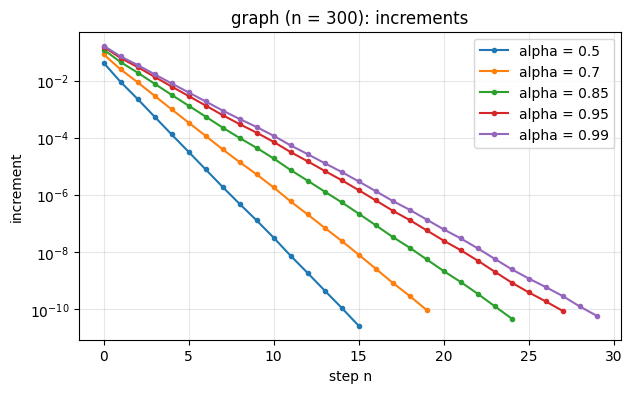

In [28]:
n = 300
A_rand = (rng.random((n, n)) < 5 / n).astype(int)
np.fill_diagonal(A_rand, 0)
A_rand[:, rng.choice(n, 15, replace=False)] = 0     # 15 dead ends
# YOUR CODE HERE
alphas = [0.5, 0.7, 0.85, 0.95, 0.99]
rows = []
all_inc = []

for alpha in alphas:
    P_t = google_matrix(A_rand, alpha=alpha)
    r, hist = power_markov(P_t)
    inc = hist['inc']
    all_inc.append(inc)
    ratios = []
    for h in range(len(inc) - 1):
      if 1e-9 <= inc[h] <= 1e-3:
        ratios.append(inc[h + 1] / inc[h])
    rate = np.median(ratios)

    eigenvalues = np.linalg.eigvals(P_t)
    sizes = np.abs(eigenvalues)
    sizes = np.sort(sizes)
    sizes = sizes[::-1]
    lam2 = sizes[1]
    rows.append([alpha, len(inc), rate, lam2, lam2 / alpha])

table = pd.DataFrame(rows, columns=['alpha', 'iterations', 'measured rate',
                                    '|lambda_2|', '|lambda_2| / alpha'])
display(table.round(4))

plt.figure(figsize=(7, 4))
for alpha, inc in zip(alphas, all_inc):
    plt.semilogy(inc, 'o-', ms=3, label=f'alpha = {alpha}')
plt.xlabel('step n')
plt.ylabel('increment')
plt.title('graph (n = 300): increments')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

---
(b) $𝝀_2$ is really close to the measured ratio means the eigenvalue tells us the speed in advance.

(c) The bound wasn't attained. For every $\alpha$ the measured rate is close to $|\lambda_2(\widetilde P, )|$ (like 0.42 vs 0.43 at $\alpha = 0.85$, basically the eigenvalue tells us the speed in advance), and both are only about half of $\alpha$. So the iteration converges much faster than the bound predicts: 25 steps instead of ~142 at $\alpha = 0.85$, and 30 instead of ~2290 at $\alpha = 0.99$.

**$|\lambda_2|/\alpha$** equals 0.5 for every $\alpha$. This what's in §3.2(b): every eigenvalue $\lambda \ne 1$ of $\widetilde P$ is $\alpha$ times an eigenvalue of $P_d$. This number depends only on the links of the graph, not on $\alpha$.

The bound $\alpha$ would be attained only if $P_d$ had a second eigenvalue of modulus 1 (traps, separate parts, cycles); this random graph is well connected, so it does not.

---

,alpha,iterations,measured rate,|lambda_2|,|lambda_2| / alpha
0,0.50,33,0.50,0.50,1.0
1,0.70,62,0.70,0.70,1.0
2,0.85,131,0.85,0.85,1.0
3,0.95,391,0.95,0.95,1.0
4,0.99,1833,0.99,0.99,1.0


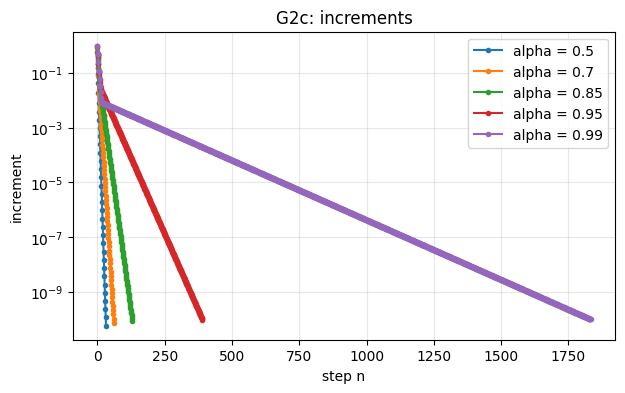

In [29]:
# for G2c
alphas = [0.5, 0.7, 0.85, 0.95, 0.99]
rows = []
all_inc = []

for alpha in alphas:
    P_t = google_matrix(G2c, alpha=alpha)
    # because G2c symmetric and converges slowly
    r, hist = power_markov(P_t, r0=np.eye(6)[0], max_iter=5000)
    inc = hist['inc']
    all_inc.append(inc)
    ratios = []
    for h in range(len(inc) - 1):
      if 1e-9 <= inc[h] <= 1e-3:
        ratios.append(inc[h + 1] / inc[h])
    rate = np.median(ratios)

    eigenvalues = np.linalg.eigvals(P_t)
    sizes = np.abs(eigenvalues)
    sizes = np.sort(sizes)
    sizes = sizes[::-1]
    lam2 = sizes[1]
    rows.append([alpha, len(inc), rate, lam2, lam2 / alpha])

table = pd.DataFrame(rows, columns=['alpha', 'iterations', 'measured rate',
                                    '|lambda_2|', '|lambda_2| / alpha'])
display(table.round(4))

plt.figure(figsize=(7, 4))
for alpha, inc in zip(alphas, all_inc):
    plt.semilogy(inc, 'o-', ms=3, label=f'alpha = {alpha}')
plt.xlabel('step n')
plt.ylabel('increment')
plt.title('G2c: increments')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

---
The bound is attained, and the iteration counts (131 at $\alpha$ = 0.85, 1833 at $\alpha$ = 0.99) match our predictions of about 142 and 2290.

By §3.2(b), $|\lambda_2(\widetilde P)| = \alpha\,|\mu_2(P_d)|$. `G2c` has two separate parts, so $P_d$ has the eigenvalue 1 twice and $|\mu_2| = 1$, giving $|\lambda_2| = \alpha$. For the random graph $|\mu_2| \approx 0.49$.
So for second eigenvalue $|\lambda_2(\widetilde P)|$  we'll multiply 1 by $\alpha$ which will be $\alpha$ so the bound will be obtained.

The real web has many groups of pages with no links out, so the `G2c` case is the realistic one: PageRank converges at rate $\alpha$.



---

---
## 5. Matrix-free PageRank on $10^5$ pages

### 5.1 The graph
The cell below builds a directed graph with about $10^5$ pages and stores its adjacency matrix in sparse form, with our convention $G_{jk} = 1 \iff k\to j$. It has two parts:
* $100\,000$ pages generated by `networkx.scale_free_graph`, a standard model of web-like graphs with a few very popular pages;
* $300$ **spider traps**: groups of three pages that receive one link from the main graph but link only among themselves — the structure of pages 0–1 in `G6`, and common on the real web (link farms, closed sites).

`[TBD: replace by a real web or citation graph once the dataset is decided; the code below should then only need a different loader.]`

**Question 5.1.** How much memory would the dense matrix $\widetilde P$ need in double precision? How much does the sparse $G$ need (look at `G.data.nbytes + G.indices.nbytes + G.indptr.nbytes`)?

In [30]:
t0 = time.time()
g = nx.DiGraph(nx.scale_free_graph(100_000, seed=2026))
g.remove_edges_from(nx.selfloop_edges(g))
for t in range(300):                                   # spider traps: a, b, c link only among themselves
    a, b, c = 100_000 + 3 * t + np.arange(3)
    g.add_edges_from([(a, b), (b, c), (c, a), (a, c)])
    g.add_edge(int(rng.integers(100_000)), a)          # one way in, no way out
n_big = g.number_of_nodes()
G_big = nx.to_scipy_sparse_array(g, format='csr', dtype=float).T.tocsc()   # G[j, k] = 1 iff k -> j
print(f'{n_big} pages, {G_big.nnz} links, built in {time.time() - t0:.1f} s')

sparse_bytes = G_big.data.nbytes + G_big.indices.nbytes + G_big.indptr.nbytes
print(f'sparse G: {sparse_bytes / 1e6:.2f} MB')

100900 pages, 194086 links, built in 3.7 s
sparse G: 3.91 MB


---
The dense matrix $\widetilde P$ is n x n so there will be 100900 x 100900  numbers, each 8 bytes: $100,900^2 × 8 ≈ 8.1 × 10^{10}$ bytes ≈ 81 GB which won't even fit here because Colab has 12.7 GB RAM.

The sparse matrix $G$ it will be the sum of all three arrays so as printed it needs only 3.91 MB.

---

### 5.2 Never form $\widetilde P$
Show that
$$
\widetilde P\mathbf{x} = \alpha P\mathbf{x} + \frac{\alpha\,(\mathbf{d}^\top\mathbf{x}) + (1-\alpha)\,(\mathbf{1}^\top\mathbf{x})}{n}\,\mathbf{1},
$$
so one step costs one sparse matrix-vector product plus $O(n)$. Then implement `google_matvec(G, alpha)`, which builds the sparse $P$ and the vector $\mathbf{d}$ **once** and returns a function `x -> P_tilde @ x`. Scale the columns of $G$ with a sparse diagonal matrix (`sp.diags`), not with a loop.

---
$\widetilde P$ has three parts: following links ($\alpha P$), jumping from dead ends ($\frac{\alpha}{n}\mathbf{1}\mathbf{d}^\top$) and random jumps ($\frac{1-\alpha}{n}\mathbf{1}\mathbf{1}^\top$):
$$
\widetilde P\mathbf{x} = \alpha P\mathbf{x} + \frac{\alpha}{n}\,\mathbf{1}\mathbf{d}^\top\mathbf{x} + \frac{1-\alpha}{n}\,\mathbf{1}\mathbf{1}^\top\mathbf{x}.
$$
Here $\mathbf{d}^\top\mathbf{x}$ is the total probability on dead ends and $\mathbf{1}^\top\mathbf{x}$ is the total probability: both are just numbers. Multiplying a number by $\mathbf{1}$ means adding it to every page. So
$$
\widetilde P\mathbf{x} = \alpha P\mathbf{x} + \frac{\alpha\,(\mathbf{d}^\top\mathbf{x}) + (1-\alpha)\,(\mathbf{1}^\top\mathbf{x})}{n}\,\mathbf{1}.
$$

**Cost:** $P\mathbf{x}$ is one sparse product (194,086 links), and the rest is two sums and adding one number to every entry, $O(n)$.



---

In [31]:
def google_matvec(G, alpha=0.85):
    '''Return a function x -> P_tilde @ x; G is sparse with G[j, k] = 1 iff k -> j.'''
    # YOUR CODE HERE
    n = G.shape[0]
    N = np.asarray(G.sum(axis=0)).ravel()
    prob = np.divide(1, N, out=np.zeros_like(N), where=N > 0)
    diag = sp.diags(prob)
    P = G @ diag
    is_dead = N == 0
    d = is_dead.astype(float)
    def function(x):
      Px = P @ x
      dx = d @ x
      return alpha * Px + (alpha * dx + (1 - alpha) * x.sum()) / n
    return function

### 5.3 Run it
1. Check `google_matvec` against `google_matrix` on `A_rand` from §4 (same $\alpha$, random $\mathbf{x}$).
2. Run `power_markov` with `google_matvec(G_big, 0.85)`, `tol=1e-10`, `r0` uniform. Report the number of iterations, the time per iteration, and compare the iteration count with the bound from §4(a) and with the measured rate. Which feature of this graph decides the rate? *(Optional check: drop the traps and rerun.)*
4. How much total rank sits in the 900 trap pages, although they are under 1% of the pages?
3. Independent check: compare your ranks with `nx.pagerank(g, alpha=0.85, tol=1e-12)` in the 1-norm. (Both use the same dead-end rule.)

In [32]:
# YOUR CODE HERE
# 1
x = rng.random(A_rand.shape[0])
A_sparse = sp.csc_array(A_rand, dtype=float)

fast = google_matvec(A_sparse, 0.85)(x)
slow = google_matrix(A_rand, 0.85) @ x

print('1-norm difference:', np.linalg.norm(fast - slow, ord=1))

# 2
t0 = time.perf_counter()
r_big, hist_big = power_markov(google_matvec(G_big, 0.85), r0=np.ones(n_big) / n_big)
total_time = time.perf_counter() - t0

print('\nnumber of iterations:', len(hist_big['inc']))
print('time per iteration:', total_time / len(hist_big['inc']))
bound = np.log(1e-10) / np.log(0.85)
print('bound from 4(a):', bound)

inc = hist_big['inc']
ratios = []
for h in range(len(inc) - 1):
    if 1e-9 <= inc[h] <= 1e-3:
        ratios.append(inc[h + 1] / inc[h])
rate = np.median(ratios)
print('measured rate:', rate)

# 3
trap_rank = r_big[100_000:].sum()
print(f'\nrank in trap pages: {trap_rank:.4f}')

# 4
nx_pr = nx.pagerank(g, alpha=0.85, tol=1e-12)
nx_list = []
for p in g.nodes():
  nx_list.append(nx_pr[p])

nx_list = np.array(nx_list)
difference = np.linalg.norm(r_big - nx_list, ord=1)
print('\ndifference our ranks vs nx: ', difference)

1-norm difference: 1.9512169657787126e-14

number of iterations: 109
time per iteration: 0.0064923906605503815
bound from 4(a): 141.6810398708398
measured rate: 0.8460227703623663

rank in trap pages: 0.0327

difference our ranks vs nx:  5.001288378854925e-07


---
2.

Results: 109 iterations, ≈ 15 ms per iteration. The bound from §4(a) is ≈ 142, and the measured rate is 0.847 ≈ α, as predicted.

108 < 142 because the bound assumes all the error shrinks at rate α. Here most of it is in the main graph and dies fast; only the small part in the traps is slow.

Spider traps decide the rate. Each trap is a closed group of pages, so surfers leave it only by the random jump. This gives $\tilde P$ an eigenvalue $\alpha$, so the rate is $\alpha = 0.85$, the slowest possible.

3.

The rank in trap pages is 3.27%, if rank were spread fairly, they'd hold about 0.9% of the total rank.

4.
r - r_nx $ \approx 5 \cdot 10^{-7}$, so the results agree. The gap comes from networkx stopping earlier (at about $10^{-7}$ precision while ours is at about $10^{-10}$).

---

### 5.4 What does the ranking say?
List the ten top pages by PageRank and the ten top pages by **in-degree** (number of in-links). How many pages are on both lists? Find one page that ranks much higher by PageRank than by in-degree, look at who links to it, and explain the difference in one or two sentences.

In [35]:
# YOUR CODE HERE
r_big_10 = np.argsort(r_big)[::-1][:10]
G_sums = np.asarray(G_big.sum(axis=1)).ravel()
in_link_10 = np.argsort(G_sums)[::-1][:10]

print('top pages by rank:               ', r_big_10)
print('top pages by number of in-links: ', in_link_10)

to_73 = G_big[73, :].toarray().ravel()
links_73 = np.nonzero(to_73)[0]
order = np.argsort(r_big[links_73])[::-1][:5]
top_sources = links_73[order]
print('strongest pages linking to 73:', top_sources)
print('their ranks:', r_big[top_sources])

out_deg = np.asarray(G_big.sum(axis=0)).ravel()
print('out-degree of page 2:', out_deg[2])

top pages by rank:                [  2   0   1  33  92  25  15 114  75  73]
top pages by number of in-links:  [  2   0   1  33  92  25  15  75 114 105]
strongest pages linking to 73: [ 2  0 15 75 49]
their ranks: [0.08062702 0.04035784 0.00414064 0.00310476 0.00281982]
out-degree of page 2: 77.0


---
9 out of 10 pages are on both lists. PageRank ranks page 73 higher than page 105 even though 73 has fewer in-links. One of its in-links comes from page 2, the most important page, which has only 77 out-links. So even 1/77 of page 2's surfers is a lot. That's why page 73 got into the PageRank list, because it counts who links to a page, not just how many links it has.




---

---
## 6. Conclusions
In a few sentences: what did you learn, what was harder than expected, and which result surprised you? If you hit a wall you could not get past, describe it here **and** in your `README`.

---
I learned that PageRank is the stationary distribution of a Markov chain (the eigenvector of $\tilde P$ with eigenvalue 1), and that the damping factor $\alpha$ makes it unique and makes the power method converge with rate at most $\alpha$.

This lab felt easier than the previous one because graphs and surfers are in my opinion easier to imagine, and I enjoyed the dead-end fix. The hardest part was the theory in §3.2, especially the proof why the other eigenvalues of $\tilde P$ are $\alpha$ times eigenvalues of $P_d$. The sparse approach was confusing at first but then it was fine. What surprised me most: under 1% of the pages (the spider traps) made the convergence rate almost exactly $\alpha$, the slowest possible.

---

---
# ★ Extension
Do **at most one** extension for the whole lab (B1 here, or A1/A2 in the Core A notebook). The point is awarded for **a defended finding**: end with a short paragraph headed *Finding*.

## ★ B1. A random walk on a ring: circulants and the FFT
On the cycle of $n$ pages, $k \to k\pm1 \pmod n$, the **lazy** random walk stays put with probability $\tfrac12$ and moves to each neighbour with probability $\tfrac14$:
$$
W = \tfrac12 I + \tfrac14\,(S + S^\top),
$$
where $S$ is the cyclic shift ($S\mathbf{e}_k = \mathbf{e}_{k+1 \bmod n}$). $W$ is a **circulant**: each column is the previous one shifted down by one. By Lecture 3.2 every circulant is diagonalised by the Fourier basis, and its eigenvalues are the DFT $\hat{\mathbf{c}}$ of its first column $\mathbf{c}$.

1. For $n = 8$, build $W$, compute `np.fft.fft(c)` and compare with `np.linalg.eigvals(W)`. Verify numerically that each column of the DFT matrix is an eigenvector.
2. Derive $\lambda_k = \tfrac12 + \tfrac12\cos(2\pi k/n)$. Hence $|\lambda_2| = \tfrac12\bigl(1 + \cos\tfrac{2\pi}n\bigr) \approx 1 - \pi^2/n^2$. **Predict** how the number of steps needed to get within $10^{-6}$ (in the 1-norm) of the uniform distribution, starting from $\mathbf{e}_0$, grows with $n$. Measure it for $n = 10, 20, 40, 80, 160$ and compare on a log-log plot.
3. Why must the walk be lazy? Compute the eigenvalues of the non-lazy walk $\tfrac12(S+S^\top)$ for even $n$ and connect the answer with `G4` in §3.1.
4. Implement `circulant_matvec(c, x)` with two FFTs and one inverse FFT (no matrix). Check it against `W @ x`. Time both for $n = 2^8, \dots, 2^{12}$ (dense) and up to $2^{20}$ (FFT only), and plot the times on log-log axes with reference slopes $n^2$ and $n\log n$. Name one data-science operation that is exactly this matvec.

In [34]:
# YOUR CODE HERE